In [9]:
!pip install -q langgraph langchain-groq python-dotenv


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\mengj\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [10]:
%pip install -U langgraph

Note: you may need to restart the kernel to use updated packages.


In [11]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

In [12]:


os.environ["GROQ_API_KEY"] = "YOUR_GROQ_API_KEY"

In [13]:
from langgraph.graph import StateGraph, START, END

print("LangGraph imported successfully!")

LangGraph imported successfully!


In [15]:
from typing import TypedDict

In [16]:
class AssignmentState(TypedDict):
    assignment_text: str
    assignment_topic: str
    assignment_summary: str
    assignment_evaluation: str
    student_feedback: str

In [17]:
import os

In [18]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.environ["GROQ_API_KEY"]
)

In [19]:
def assignment_summary(state: AssignmentState):
    response = llm.invoke(
        f"Based on the assignment topic {state['assignment_topic']}, please summarize this assignment: {state['assignment_text']}")
    return {"assignment_summary": response.content}

def assignment_evaluation(state: AssignmentState):
    response = llm.invoke(
        f"""Evaluate the assignment summary based on the assignment topic
        and marking criteria. Assignment Topic: {state['assignment_topic']}. Assignment Summary: {state['assignment_summary']}
        Marking Criteria:
        1. Relevance to the topic
        2. Accuracy of information
        3. Completeness of content
        4. Clarity and organization

        Provide a detailed evaluation.
        """
    )
    return {"assignment_evaluation": response.content}

def student_feedback(state: AssignmentState):
    response = llm.invoke(
        f"Based on the assignment summary {state['assignment_summary']}, provide feedback using the assignment evaluation: {state['assignment_evaluation']} and assignment topic {state['assignment_topic']}")
    return {"student_feedback": response.content}

In [20]:
d = {
    "assignment_topic": "The Impact of Artificial Intelligence on Education",
    "assignment_text": """
    Artificial Intelligence is changing the education sector.
    AI tools help students learn through personalized learning,
    provide instant feedback and support teachers in evaluating
    student performance. AI-powered chatbots can answer student
    questions and intelligent tutoring systems can help students
    understand difficult topics. However, excessive dependence
    on AI may reduce critical thinking and create privacy concerns.
    """
}

In [22]:
from langgraph.graph import StateGraph, START, END

In [24]:
workflow = StateGraph(AssignmentState)

workflow.add_node("assignment_summary", assignment_summary)
workflow.add_node("assignment_evaluation", assignment_evaluation)
workflow.add_node("student_feedback", student_feedback)

In [25]:
workflow.add_edge(START, "assignment_summary")
workflow.add_edge("assignment_summary", "assignment_evaluation")
workflow.add_edge("assignment_evaluation", "student_feedback")
workflow.add_edge("student_feedback", END)

In [26]:
app = workflow.compile()

In [28]:
from dotenv import load_dotenv
import os
from langchain_groq import ChatGroq

load_dotenv(override=True)

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    api_key=os.environ["GROQ_API_KEY"]
)

response = llm.invoke("Say Hello")
print(response.content)

Hello! 👋 How can I help you today?


In [29]:
result = app.invoke(d)

In [30]:
print("ASSIGNMENT SUMMARY:")
print(result["assignment_summary"])

print("\nASSIGNMENT EVALUATION:")
print(result["assignment_evaluation"])

print("\nSTUDENT FEEDBACK:")
print(result["student_feedback"])

ASSIGNMENT SUMMARY:
**Summary**

Artificial Intelligence is transforming education by providing personalized learning experiences, instant feedback, and valuable support for teachers in assessing student performance. AI-powered chatbots answer student queries on demand, while intelligent tutoring systems help clarify challenging concepts. Despite these benefits, overreliance on AI can erode critical thinking skills and raise significant privacy concerns regarding student data.

ASSIGNMENT EVALUATION:
### Evaluation of the Assignment Summary  
**Topic:** *The Impact of Artificial Intelligence on Education*  
**Summary Text:**  
> *Artificial Intelligence is transforming education by providing personalized learning experiences, instant feedback, and valuable support for teachers in assessing student performance. AI‑powered chatbots answer student queries on demand, while intelligent tutoring systems help clarify challenging concepts. Despite these benefits, overreliance on AI can erode c

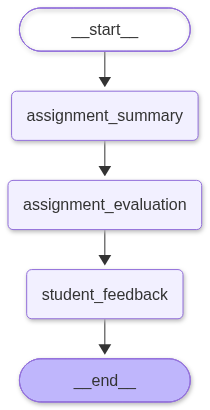

In [ ]:
workflow.compile()

Routing Workflow

In [31]:
class RoutingState(TypedDict):
    user_query: str
    decision: str
    final_output: str

In [32]:
user_input = "write poem about Snow"

In [33]:
llm.invoke(f"please classify user input {user_input} into story, joke and poem return only label")

AIMessage(content='poem', additional_kwargs={'reasoning_content': 'The user says: "please classify user input write poem about Snow into story, joke and poem return only label". So they want us to classify the user input "write poem about Snow" into categories: story, joke, poem. We need to return only the label. So we need to decide which category "write poem about Snow" is. The input is a request: "write poem about Snow". That is a request to write a poem. So it\'s a poem request. So the classification is "poem". So we output "poem".'}, response_metadata={'token_usage': {'completion_tokens': 124, 'prompt_tokens': 88, 'total_tokens': 212, 'completion_time': 0.127183244, 'completion_tokens_details': {'reasoning_tokens': 113}, 'prompt_time': 0.004276428, 'prompt_tokens_details': None, 'queue_time': 0.367054818, 'total_time': 0.131459672}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'mo

In [34]:
from pydantic import BaseModel, Field


In [38]:
from typing_extensions import Literal

class Decision(BaseModel):
    decision: Literal["poem", "story", "joke"] = Field(
        description="Based on input take label decision: story, poem and joke"
    )

In [39]:
routing_llm = llm.with_structured_output(Decision)

In [40]:
def routing_agent(state: RoutingState):
    response = routing_llm.invoke(
        f"please classify user input {state['user_query']} into story, joke and poem return only label"
    )
    return {"decision": response.decision}


def write_poem(state: RoutingState):
    response = llm.invoke(f"write a poem on this topic {state['user_query']}")
    return {"final_output": response.content}


def write_joke(state: RoutingState):
    response = llm.invoke(f"write a joke on this topic {state['user_query']}")
    return {"final_output": response.content}


def write_story(state: RoutingState):
    response = llm.invoke(f"write a story on this topic {state['user_query']}")
    return {"final_output": response.content}

In [41]:
workflow = StateGraph(RoutingState)

In [42]:
workflow.add_node("routing_agent", routing_agent)
workflow.add_node("write_joke", write_joke)
workflow.add_node("write_poem", write_poem)
workflow.add_node("write_story", write_story)

In [43]:
def route_decision(state: RoutingState):
    # Return the node name you want to visit next
    if state["decision"] == "story":
        return "story"
    elif state["decision"] == "joke":
        return "joke"
    elif state["decision"] == "poem":
        return "poem"

In [44]:
workflow.add_edge(START, "routing_agent")

workflow.add_conditional_edges(
    "routing_agent",
    route_decision,
    {
        "story": "write_story",
        "poem": "write_poem",
        "joke": "write_joke"
    }
)

workflow.add_edge("write_joke", END)
workflow.add_edge("write_poem", END)
workflow.add_edge("write_story", END)

In [45]:
routing_workflow = workflow.compile()

In [46]:
result = routing_workflow.invoke({
    "user_query": user_input
})

print(result["final_output"])

**When the World Turns White**

The air itself becomes a quiet hush,  
a breath held between the last warm sun and the first star.  
Snow, the silent visitor, drapes the city in lace—  
each flake a fleeting, perfect promise.

It falls in a slow, patient ballet,  
tossed by wind, twirled by the night,  
landing on rooftops, on branches, on the backs of passing dogs.  
A hush falls over the street, the traffic, the chatter.

The ground, once a mosaic of colors, is now a sheet of glass,  
a mirror that reflects the pale sky and the flicker of streetlamps.  
Footprints appear, then vanish—an ever‑changing story  
written and erased by the next gentle drift.

Children laugh, their cheeks rosy, their breath a mist of fire,  
building castles from the soft, powdery snow,  
their fingers tracing the edges of a winter wonderland.  
Every touch is a memory, every step a song.

And when the night settles, the world glows in silver light,  
the snow a quiet cathedral where silence sings.  
In tha